# Proyecto integrador de Ciencia de Datos e Inteligencia Artificial

**Fase 2: Preprocesamiento, ingeniería de variables y modelos base**  
**Asignatura:** Ciencia de Datos  
**Programa:** Maestría en Inteligencia Artificial  
**Estudiante:** Jennifer Juliana Bayona Rojas

Enlace del notebook: https://colab.research.google.com/drive/1BNd65NmkIf1lHDseDnr7EXpsKfaWUbGF?usp=sharing

En esta fase se prepara la información para regresión y clasificación, se separan los datos en entrenamiento, validación y prueba, y se establecen modelos de referencia. Se mantiene el alcance definido en la Fase 1.

## Preparación del entorno

Se importan las bibliotecas para manipulación de datos, visualización, preprocesamiento y evaluación de modelos. Se fija la presentación de tablas para facilitar la lectura.

In [2]:
# Manipulación y análisis de datos
import pandas as pd
import numpy as np

# Visualización de datos
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display

# Manipulación de archivos en disco
import os

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    average_precision_score
)

# Configuración de visualización de tablas
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# Función reutilizable para visualizar las matrices de confusión
def graficar_matriz_confusion(matriz, titulo):
    fig, ax = plt.subplots(figsize=(6.2, 4.7))
    ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=["Completado (0)", "Devuelto (1)"]
    ).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(titulo, pad=12)
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")
    fig.tight_layout()
    plt.show()


## 1. Carga del conjunto de datos

Se utiliza `base_depurada_fase1.csv`, el archivo exportado al finalizar la Fase 1. Cada fila representa un pedido. A partir de esta tabla se preparan los conjuntos para estimar ventas netas en USD y clasificar pedidos completados y devueltos.

In [3]:
# Descargar los archivos .csv con la base de datos que se usaran en el trabajo
nombre_archivo = 'base_datos.csv'
if not os.path.exists(nombre_archivo):
    !gdown 169OhAcFjU0z9awFNg0AZDyWQudonCMDD --output $nombre_archivo


Downloading...
From: https://drive.google.com/uc?id=169OhAcFjU0z9awFNg0AZDyWQudonCMDD
To: /content/base_datos.csv
100% 18.5M/18.5M [00:00<00:00, 215MB/s]


In [4]:
# Crear el dataframe
df_master = pd.read_csv(nombre_archivo)
display(df_master.head())

,order_id,customer_id,order_date,currency,customer_age,customer_segment,sales_channel,quantity,net_sales,order_status,customer_country,payment_method,shipping_method,marketing_channel,estimated_delivery_days,delivery_days,loyalty_points_redeemed,review_sentiment
0,ORD-301242,CUST-003102,2023-11-06,USD,55,Consumer,Mobile App,5,945.400,Completed,USA,Digital Wallet,Standard,Direct,3.000,3.000,44,Positive
1,ORD-773460,CUST-003124,2025-12-24,EUR,26,Premium,Website,8,"2,018.410",Completed,Germany,Debit Card,Economy,Direct,10.000,10.000,171,Positive
2,ORD-449374,CUST-012496,2021-07-05,USD,69,Premium,Mobile App,5,468.350,Completed,USA,Cash on Delivery,Express,YouTube,3.000,3.000,16,Positive
3,ORD-567636,CUST-023928,2023-01-21,USD,65,Consumer,Social Media,2,546.520,Completed,USA,Debit Card,Express,Email Marketing,2.000,2.000,10,Positive
4,ORD-820028,CUST-012730,2022-05-13,INR,34,Consumer,Social Media,6,"2,785.270",Completed,India,Digital Wallet,Standard,Direct,5.000,6.000,147,Neutral


### 1.1 Diagnóstico inicial

Se revisan dimensiones, tipos, faltantes, duplicados y distribución de estados y monedas. Esto permite verificar que se continúa trabajando con la tabla de pedidos definida en la Fase 1.

In [5]:
# Diagnóstico inicial de la base de datos

# Dimensiones del dataset
print("DIMENSIONES DEL DATASET")
print(f"Registros: {df_master.shape[0]:,}")
print(f"Variables: {df_master.shape[1]}")

# Tipos de datos y valores faltantes
diagnostico = pd.DataFrame({
    "Tipo de dato": df_master.dtypes,
    "Valores faltantes": df_master.isnull().sum(),
    "Porcentaje faltante (%)": (
        df_master.isnull().mean() * 100
    ).round(2)
})

print("\nDIAGNÓSTICO DE VARIABLES")
display(diagnostico)

# Verificar duplicados
print("\nREGISTROS DUPLICADOS")
print("Filas duplicadas:", df_master.duplicated().sum())
print("Pedidos duplicados:", df_master["order_id"].duplicated().sum())

# Distribución de estados y monedas
print("\nESTADOS DE LOS PEDIDOS")
display(df_master["order_status"].value_counts(dropna=False))

print("\nMONEDAS REGISTRADAS")
display(df_master["currency"].value_counts(dropna=False))

# Vista preliminar
print("\nPRIMEROS REGISTROS")
display(df_master.head())


DIMENSIONES DEL DATASET
Registros: 138,116
Variables: 18

DIAGNÓSTICO DE VARIABLES


,Tipo de dato,Valores faltantes,Porcentaje faltante (%)
order_id,object,0,0.000
customer_id,object,0,0.000
order_date,object,0,0.000
currency,object,0,0.000
customer_age,int64,0,0.000
customer_segment,object,0,0.000
sales_channel,object,0,0.000
quantity,int64,0,0.000
net_sales,float64,0,0.000
order_status,object,0,0.000



REGISTROS DUPLICADOS
Filas duplicadas: 0
Pedidos duplicados: 0

ESTADOS DE LOS PEDIDOS


,count
order_status,
Completed,113559
Returned,9462
Cancelled,8398
Pending,6697



MONEDAS REGISTRADAS


,count
currency,
USD,82600
GBP,20235
EUR,11593
CAD,7015
AUD,6794
INR,5707
AED,4172



PRIMEROS REGISTROS


,order_id,customer_id,order_date,currency,customer_age,customer_segment,sales_channel,quantity,net_sales,order_status,customer_country,payment_method,shipping_method,marketing_channel,estimated_delivery_days,delivery_days,loyalty_points_redeemed,review_sentiment
0,ORD-301242,CUST-003102,2023-11-06,USD,55,Consumer,Mobile App,5,945.400,Completed,USA,Digital Wallet,Standard,Direct,3.000,3.000,44,Positive
1,ORD-773460,CUST-003124,2025-12-24,EUR,26,Premium,Website,8,"2,018.410",Completed,Germany,Debit Card,Economy,Direct,10.000,10.000,171,Positive
2,ORD-449374,CUST-012496,2021-07-05,USD,69,Premium,Mobile App,5,468.350,Completed,USA,Cash on Delivery,Express,YouTube,3.000,3.000,16,Positive
3,ORD-567636,CUST-023928,2023-01-21,USD,65,Consumer,Social Media,2,546.520,Completed,USA,Debit Card,Express,Email Marketing,2.000,2.000,10,Positive
4,ORD-820028,CUST-012730,2022-05-13,INR,34,Consumer,Social Media,6,"2,785.270",Completed,India,Digital Wallet,Standard,Direct,5.000,6.000,147,Neutral


## 2. Análisis del mecanismo de valores faltantes

Se contrasta la ausencia de datos de entrega y reseñas con `order_status`. Este paso es necesario **antes de decidir si corresponde imputar, eliminar o conservar** los valores faltantes.

In [6]:
# Análisis de valores faltantes por estado del pedido

columnas_nulos = ["estimated_delivery_days", "delivery_days", "review_sentiment"]

# Cantidad de valores faltantes por estado
tabla_nulos = df_master.groupby("order_status").agg(
    total_pedidos=("order_id", "count"),
    faltantes_estimados=("estimated_delivery_days",
                         lambda x: x.isna().sum()),
    faltantes_entrega=("delivery_days",
                       lambda x: x.isna().sum()),
    faltantes_sentimiento=("review_sentiment",
                           lambda x: x.isna().sum()))

# Porcentaje de faltantes por estado
for columna in ["faltantes_estimados", "faltantes_entrega", "faltantes_sentimiento"]:
    tabla_nulos[columna + "_pct"] = (
        tabla_nulos[columna] /
        tabla_nulos["total_pedidos"] * 100).round(2)

display(tabla_nulos)

# Verificar si las tres variables comparten el mismo patrón
mismo_patron = (df_master[columnas_nulos].isna().nunique(axis=1).eq(1).all())

print("¿Las tres variables comparten el mismo patrón de nulos?")
print(mismo_patron)


,total_pedidos,faltantes_estimados,faltantes_entrega,faltantes_sentimiento,faltantes_estimados_pct,faltantes_entrega_pct,faltantes_sentimiento_pct
order_status,,,,,,,
Cancelled,8398,8398,8398,8398,100.000,100.000,100.000
Completed,113559,0,0,0,0.000,0.000,0.000
Pending,6697,6697,6697,6697,100.000,100.000,100.000
Returned,9462,9462,9462,9462,100.000,100.000,100.000


¿Las tres variables comparten el mismo patrón de nulos?
True


**Patrón de ausencia.** Cada uno de los tres campos (`estimated_delivery_days`, `delivery_days` y `review_sentiment`) presenta **24.557 faltantes (17,78 %)**. Los tres faltan en las mismas filas. Están completos para los pedidos `Completed` y ausentes para los pedidos `Cancelled`, `Pending` y `Returned`.

La relación con el estado del pedido aporta evidencia contra la ausencia completamente al azar (MCAR). El patrón es compatible con un mecanismo MAR condicionado al estado observado. Distinguirlo de un mecanismo MNAR requeriría conocer cómo se registraron estos campos en la fuente.

**Decisión.** Los faltantes se conservan en la tabla para el análisis exploratorio. Los tres campos y sus indicadores de ausencia quedan fuera de los modelos. En clasificación, la ausencia distinguiría directamente `Completed` de `Returned` y revelaría la variable objetivo.

### 2.1 Limpieza y normalización básica

Se preserva una copia del conjunto original, se convierten fechas y se eliminan espacios sobrantes de las columnas de texto. No se eliminan registros ni se reemplazan datos ausentes sin justificación.

In [7]:
#  Limpieza y estandarización inicial

# Crear copia de seguridad
df_original = df_master.copy()

# Convertir fecha al formato datetime
df_master["order_date"] = pd.to_datetime(df_master["order_date"], errors="coerce")
if df_master["order_date"].isna().any():
    raise ValueError("Hay fechas inválidas. Revisar antes de crear variables temporales.")

# Limpiar espacios en variables categóricas
columnas_texto = df_master.select_dtypes(include=["object", "string"]).columns

for col in columnas_texto:
    df_master[col] = (df_master[col].astype("string").str.strip().replace("", pd.NA))

# Verificar resultados
print("RESULTADOS DE LA LIMPIEZA")
print("Registros originales:", len(df_original))
print("Registros actuales:", len(df_master))
print("Duplicados:", df_master.duplicated().sum())
print("Fechas inválidas:", df_master["order_date"].isna().sum())

print("\nVALORES FALTANTES CONSERVADOS:")
print(df_master.isna().sum()[df_master.isna().sum() > 0])

print("\nTIPOS DE DATOS ACTUALIZADOS:")
display(df_master.dtypes.to_frame("Tipo de dato"))

print("\nVISTA PRELIMINAR:")
display(df_master.head())


RESULTADOS DE LA LIMPIEZA
Registros originales: 138116
Registros actuales: 138116
Duplicados: 0
Fechas inválidas: 0

VALORES FALTANTES CONSERVADOS:
estimated_delivery_days    24557
delivery_days              24557
review_sentiment           24557
dtype: int64

TIPOS DE DATOS ACTUALIZADOS:


,Tipo de dato
order_id,string[python]
customer_id,string[python]
order_date,datetime64[ns]
currency,string[python]
customer_age,int64
customer_segment,string[python]
sales_channel,string[python]
quantity,int64
net_sales,float64
order_status,string[python]



VISTA PRELIMINAR:


,order_id,customer_id,order_date,currency,customer_age,customer_segment,sales_channel,quantity,net_sales,order_status,customer_country,payment_method,shipping_method,marketing_channel,estimated_delivery_days,delivery_days,loyalty_points_redeemed,review_sentiment
0,ORD-301242,CUST-003102,2023-11-06,USD,55,Consumer,Mobile App,5,945.400,Completed,USA,Digital Wallet,Standard,Direct,3.000,3.000,44,Positive
1,ORD-773460,CUST-003124,2025-12-24,EUR,26,Premium,Website,8,"2,018.410",Completed,Germany,Debit Card,Economy,Direct,10.000,10.000,171,Positive
2,ORD-449374,CUST-012496,2021-07-05,USD,69,Premium,Mobile App,5,468.350,Completed,USA,Cash on Delivery,Express,YouTube,3.000,3.000,16,Positive
3,ORD-567636,CUST-023928,2023-01-21,USD,65,Consumer,Social Media,2,546.520,Completed,USA,Debit Card,Express,Email Marketing,2.000,2.000,10,Positive
4,ORD-820028,CUST-012730,2022-05-13,INR,34,Consumer,Social Media,6,"2,785.270",Completed,India,Digital Wallet,Standard,Direct,5.000,6.000,147,Neutral


## 3. Tratamiento razonado de valores atípicos

Los valores detectados con IQR se consideran **posibles atípicos**, no necesariamente registros erróneos. La estrategia de tratamiento debe conservar la coherencia comercial de los pedidos.

### 3.1 Detección y evaluación de valores atípicos

Se usa la regla **1,5 × IQR** en variables numéricas y se analiza `net_sales` **por moneda**. Se comprueban también valores incoherentes como cantidades no positivas o ventas negativas.

In [8]:
# Función para detectar outliers mediante IQR
def detectar_outliers(serie):
    datos = serie.dropna()

    q1 = datos.quantile(0.25)
    q3 = datos.quantile(0.75)
    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    outliers = (
        (datos < limite_inferior) |
        (datos > limite_superior)
    ).sum()

    return pd.Series({
        "Mínimo": datos.min(),
        "Máximo": datos.max(),
        "Límite inferior": round(limite_inferior, 2),
        "Límite superior": round(limite_superior, 2),
        "Outliers": outliers,
        "% Outliers": round(outliers / len(datos) * 100, 2)
    })

# Variables numéricas
columnas_numericas = [ "customer_age", "quantity","loyalty_points_redeemed", "estimated_delivery_days", "delivery_days"]

print("OUTLIERS EN VARIABLES NUMÉRICAS")

resultado_iqr = pd.DataFrame({
    col: detectar_outliers(df_master[col])
    for col in columnas_numericas}).T

display(resultado_iqr)

# Ventas separadas por moneda
print("\nOUTLIERS EN VENTAS POR MONEDA")

resultado_ventas = pd.DataFrame({
    moneda: detectar_outliers(grupo["net_sales"])
    for moneda, grupo in df_master.groupby("currency")
}).T

display(resultado_ventas)

# Verificación de valores potencialmente incoherentes
print("\nVERIFICACIÓN DE VALORES")

print("Edades negativas:",
      (df_master["customer_age"] < 0).sum())

print("Cantidades menores o iguales a cero:",
      (df_master["quantity"] <= 0).sum())

print("Ventas negativas:",
      (df_master["net_sales"] < 0).sum())

print("Días de entrega negativos:",
      (df_master["delivery_days"] < 0).sum())

print("Puntos de fidelización negativos:",
      (df_master["loyalty_points_redeemed"] < 0).sum())


OUTLIERS EN VARIABLES NUMÉRICAS


,Mínimo,Máximo,Límite inferior,Límite superior,Outliers,% Outliers
customer_age,18.000,74.000,-10.000,102.000,0.000,0.000
quantity,1.000,24.000,-4.500,15.500,"1,197.000",0.870
loyalty_points_redeemed,0.000,"1,063.000",-99.000,173.000,"9,172.000",6.640
estimated_delivery_days,0.000,10.000,-4.000,12.000,0.000,0.000
delivery_days,0.000,14.000,-5.500,14.500,0.000,0.000



OUTLIERS EN VENTAS POR MONEDA


,Mínimo,Máximo,Límite inferior,Límite superior,Outliers,% Outliers
AED,18.330,"9,188.690","-1,409.840","3,526.210",186.000,4.460
AUD,11.860,"9,568.580","-1,483.120","3,688.890",321.000,4.720
CAD,10.420,"9,879.970","-1,536.760","3,822.310",287.000,4.090
EUR,11.460,"10,392.920","-1,688.410","4,080.150",484.000,4.170
GBP,7.750,"12,593.510","-1,600.580","3,954.920",943.000,4.660
INR,10.780,"10,520.840","-1,627.860","3,936.900",260.000,4.560
USD,5.800,"16,218.000","-1,445.890","3,562.800","3,882.000",4.700



VERIFICACIÓN DE VALORES
Edades negativas: 0
Cantidades menores o iguales a cero: 0
Ventas negativas: 0
Días de entrega negativos: 0
Puntos de fidelización negativos: 0


**Decisión sobre los atípicos.** La regla IQR marcó **1.197 pedidos (0,87 %)** por cantidad, **9.172 (6,64 %)** por puntos canjeados y **3.882 pedidos en USD (4,70 %)** por venta neta. Los controles de coherencia mostraron cantidades e importes positivos. Por ello, se conservan estos pedidos para representar también las compras grandes y de alto valor.

En los puntos canjeados se aplica `log1p`, que conserva los ceros y comprime los valores altos. La tabla de la sección siguiente compara la asimetría antes y después de la transformación.

### 3.2 Transformación logarítmica de puntos de fidelización

`loyalty_points_redeemed` presenta asimetría y valores extremos detectados con IQR. Se aplica `log1p(x)` para reducir su influencia sin perder los ceros ni eliminar pedidos. Es una transformación determinista; antes de usarla como predictor debe verificarse que la variable se conozca al momento de la compra.

In [9]:
df_master["loyalty_points_log"] = np.log1p(df_master["loyalty_points_redeemed"])

columnas_puntos = ["loyalty_points_redeemed", "loyalty_points_log"]
resumen_transformacion = df_master[columnas_puntos].describe().T
resumen_transformacion["Asimetría"] = df_master[columnas_puntos].skew()
display(resumen_transformacion.round(3))

print("Registros conservados", len(df_master))
print("Faltantes después de la transformación", df_master["loyalty_points_log"].isna().sum())

,count,mean,std,min,25%,50%,75%,max,Asimetría
loyalty_points_redeemed,"138,116.000",51.934,73.218,0.000,3.000,25.000,71.000,"1,063.000",2.769
loyalty_points_log,"138,116.000",2.851,1.790,0.000,1.386,3.258,4.277,6.970,-0.388


Registros conservados 138116
Faltantes después de la transformación 0


## 4. Ingeniería de variables

Se crean características temporales (`order_month`, `is_weekend`) y demográficas (`age_group`), además de la transformación de puntos. Permiten describir estacionalidad, hábitos de compra y grupos etarios.

In [10]:
# Mes de compra
df_master["order_month"] = df_master["order_date"].dt.month

# Compra realizada en fin de semana
df_master["is_weekend"] = (df_master["order_date"].dt.dayofweek >= 5).astype(int)

# 3. Grupo de edad del cliente
df_master["age_group"] = pd.cut(
    df_master["customer_age"],
    bins=[17, 29, 44, 59, float("inf")],
    labels=["18-29", "30-44", "45-59", "60+"]
)

# Verificar las nuevas variables
print("VARIABLES DERIVADAS")
display(df_master[["order_date","customer_age",
    "order_month","is_weekend","age_group"]].head(10))

print("\nDISTRIBUCIÓN POR GRUPO DE EDAD")
display(df_master["age_group"].value_counts().sort_index())

print("\nCOMPRAS ENTRE SEMANA Y FIN DE SEMANA")
display(df_master["is_weekend"].value_counts())

print("\nVALIDACIÓN")
print("Registros:", len(df_master))
print("Total de variables:", df_master.shape[1])
print("Nulos en variables derivadas:",
      df_master[[
          "order_month",
          "is_weekend",
          "age_group"
      ]].isna().sum().sum())


VARIABLES DERIVADAS


,order_date,customer_age,order_month,is_weekend,age_group
0,2023-11-06,55,11,0,45-59
1,2025-12-24,26,12,0,18-29
2,2021-07-05,69,7,0,60+
3,2023-01-21,65,1,1,60+
4,2022-05-13,34,5,0,30-44
5,2021-02-10,41,2,0,30-44
6,2021-05-03,61,5,0,60+
7,2022-10-13,43,10,0,30-44
8,2022-12-06,22,12,0,18-29
9,2023-09-19,36,9,0,30-44



DISTRIBUCIÓN POR GRUPO DE EDAD


,count
age_group,
18-29,29460
30-44,36580
45-59,35937
60+,36139



COMPRAS ENTRE SEMANA Y FIN DE SEMANA


,count
is_weekend,
0,98686
1,39430



VALIDACIÓN
Registros: 138116
Total de variables: 22
Nulos en variables derivadas: 0


La tabla queda con **22 variables**, incluidas cuatro derivadas. `order_month` permite evaluar diferencias entre meses e `is_weekend` distingue los pedidos de sábado y domingo. Ambas se calculan con información disponible al registrar la compra.

`age_group` se usa para describir la distribución por edades. Los modelos conservan `customer_age` en años cumplidos. `loyalty_points_log` se usa en el diagnóstico de fidelización. Las cuatro variables derivadas quedaron completas.

## 5. Definición de problemas y variables objetivo

- **Regresión:** predecir `net_sales` usando solo pedidos en **USD**, para no mezclar monedas.
- **Clasificación:** detectar devoluciones (`Returned = 1` y `Completed = 0`). Se excluyen `Cancelled` y `Pending` porque representan otros estados.

In [11]:
# Definición de variables objetivo

# dataset para regresión (únicamente USD)
df_regresion = df_master[df_master["currency"] == "USD"].copy()

# Variable objetivo: net_sales
print("REGRESIÓN - PREDICCIÓN DE VENTAS")
print("Registros:", len(df_regresion))
print("Variable objetivo: net_sales")
print("Moneda: USD")

# Dataset para clasificación
df_clasificacion = df_master[df_master["order_status"].isin(["Completed", "Returned"])].copy()

# Crear variable objetivo binaria
df_clasificacion["target_returned"] = (
    df_clasificacion["order_status"] == "Returned").astype(int)

print("\nCLASIFICACIÓN - DEVOLUCIÓN DE PEDIDOS")
print("Registros:", len(df_clasificacion))

# Distribución de clases
distribucion = pd.DataFrame({
    "Cantidad": df_clasificacion["target_returned"].value_counts().reindex([0, 1], fill_value=0),
    "Porcentaje (%)": (
        df_clasificacion["target_returned"]
        .value_counts(normalize=True).reindex([0, 1], fill_value=0) * 100
    ).round(2)
})

distribucion.index = ["Completado (0)", "Devuelto (1)"]
display(distribucion)

# Validación
print("\nVALIDACIÓN FINAL")
print("Registros originales:", len(df_master))
print("Registros regresión:", len(df_regresion))
print("Registros clasificación:", len(df_clasificacion))


REGRESIÓN - PREDICCIÓN DE VENTAS
Registros: 82600
Variable objetivo: net_sales
Moneda: USD

CLASIFICACIÓN - DEVOLUCIÓN DE PEDIDOS
Registros: 123021


,Cantidad,Porcentaje (%)
Completado (0),113559,92.310
Devuelto (1),9462,7.690



VALIDACIÓN FINAL
Registros originales: 138116
Registros regresión: 82600
Registros clasificación: 123021


### 5.1 Selección de predictores

Se construyen las matrices de características (`X`) y las variables objetivo (`y`) para cada problema. La selección se restringe a variables comerciales, demográficas y temporales.

In [12]:
variables_regresion = [
    "customer_age",
    "customer_segment",
    "sales_channel",
    "quantity",
    "customer_country",
    "payment_method",
    "shipping_method",
    "marketing_channel",
    "order_month",
    "is_weekend",
]

variables_clasificacion_exploratoria = [
    "currency",
    *variables_regresion,
    "loyalty_points_log",
]

X_reg = df_regresion[variables_regresion].copy()
y_reg = df_regresion["net_sales"].copy()

X_clf = df_clasificacion[variables_clasificacion_exploratoria].copy()
y_clf = df_clasificacion["target_returned"].copy()

display(pd.DataFrame({
    "Pedidos": [len(X_reg), len(X_clf)],
    "Predictores": [X_reg.shape[1], X_clf.shape[1]],
    "Faltantes en X": [X_reg.isna().sum().sum(), X_clf.isna().sum().sum()],
}, index=["Regresión", "Clasificación exploratoria"]))

,Pedidos,Predictores,Faltantes en X
Regresión,82600,10,0
Clasificación exploratoria,123021,12,0


`order_id` y `customer_id` se conservan para identificar pedidos y revisar la partición de clientes. Se excluyen de los predictores. En clasificación, `order_status` define el objetivo y `net_sales`, los campos de entrega y el sentimiento de la reseña quedan fuera de la matriz de entrada.

La regresión usa únicamente pedidos en USD, por lo que la moneda es constante. En clasificación se incluyen pedidos de distintas monedas y se conserva `currency`. Los puntos de fidelización se incorporan únicamente al experimento exploratorio de clasificación.

## 6. División en entrenamiento, validación y prueba

Se reserva **70 % para entrenamiento, 15 % para validación y 15 % para prueba**. En clasificación se aplica estratificación para conservar la proporción de pedidos devueltos.

In [13]:
# REGRESIÓN
X_reg_train, X_reg_temp, y_reg_train, y_reg_temp = train_test_split(
    X_reg, y_reg, test_size=0.30, random_state=42)

X_reg_val, X_reg_test, y_reg_val, y_reg_test = train_test_split(
    X_reg_temp, y_reg_temp, test_size=0.50, random_state=42)

# CLASIFICACIÓN (división estratificada)
X_clf_train, X_clf_temp, y_clf_train, y_clf_temp = train_test_split(
    X_clf, y_clf,
    test_size=0.30,
    stratify=y_clf,
    random_state=42)

X_clf_val, X_clf_test, y_clf_val, y_clf_test = train_test_split(
    X_clf_temp, y_clf_temp,
    test_size=0.50,
    stratify=y_clf_temp,
    random_state=42)

# Verificación de resultados
print("REGRESIÓN")
print("Entrenamiento:", X_reg_train.shape)
print("Validación:", X_reg_val.shape)
print("Prueba:", X_reg_test.shape)

print("\nCLASIFICACIÓN")
print("Entrenamiento:", X_clf_train.shape)
print("Validación:", X_clf_val.shape)
print("Prueba:", X_clf_test.shape)

# Verificar distribución de clases
print("\nPORCENTAJE DE DEVOLUCIONES POR CONJUNTO")

for nombre, y in [
    ("Entrenamiento", y_clf_train),
    ("Validación", y_clf_val),
    ("Prueba", y_clf_test)
]:
    porcentaje = y.mean() * 100
    print(f"{nombre}: {porcentaje:.2f}%")


REGRESIÓN
Entrenamiento: (57820, 10)
Validación: (12390, 10)
Prueba: (12390, 10)

CLASIFICACIÓN
Entrenamiento: (86114, 12)
Validación: (18453, 12)
Prueba: (18454, 12)

PORCENTAJE DE DEVOLUCIONES POR CONJUNTO
Entrenamiento: 7.69%
Validación: 7.69%
Prueba: 7.69%


### 6.1 Comprobación complementaria: clientes repetidos entre particiones

La división estratificada se hace por pedido. Como un cliente puede tener varios pedidos, se revisa su posible presencia en diferentes subconjuntos. Esto no invalida automáticamente el modelo, pero puede sobrestimar el desempeño si el objetivo es generalizar a **clientes nunca vistos**.

In [14]:
# Diagnóstico de clientes compartidos entre conjuntos (sin cambiar la partición)
def diagnostico_clientes_compartidos(df_origen, X_train, X_val, X_test):
    train_ids = set(df_origen.loc[X_train.index, "customer_id"].dropna())
    val_ids = set(df_origen.loc[X_val.index, "customer_id"].dropna())
    test_ids = set(df_origen.loc[X_test.index, "customer_id"].dropna())
    return pd.Series({
        "Clientes únicos en entrenamiento": len(train_ids),
        "Clientes únicos en validación": len(val_ids),
        "Clientes únicos en prueba": len(test_ids),
        "Compartidos entrenamiento-validación": len(train_ids & val_ids),
        "Compartidos entrenamiento-prueba": len(train_ids & test_ids),
        "Compartidos validación-prueba": len(val_ids & test_ids),
    })

print("DIAGNÓSTICO DE CLIENTES - REGRESIÓN")
display(diagnostico_clientes_compartidos(
    df_regresion, X_reg_train, X_reg_val, X_reg_test).to_frame("Cantidad"))

print("\nDIAGNÓSTICO DE CLIENTES - CLASIFICACIÓN")
display(diagnostico_clientes_compartidos(
    df_clasificacion, X_clf_train, X_clf_val, X_clf_test).to_frame("Cantidad"))

DIAGNÓSTICO DE CLIENTES - REGRESIÓN


,Cantidad
Clientes únicos en entrenamiento,14648
Clientes únicos en validación,8415
Clientes únicos en prueba,8448
Compartidos entrenamiento-validación,8260
Compartidos entrenamiento-prueba,8286
Compartidos validación-prueba,4718



DIAGNÓSTICO DE CLIENTES - CLASIFICACIÓN


,Cantidad
Clientes únicos en entrenamiento,24222
Clientes únicos en validación,13076
Clientes únicos en prueba,13070
Compartidos entrenamiento-validación,12668
Compartidos entrenamiento-prueba,12653
Compartidos validación-prueba,6815


La estratificación mantiene aproximadamente el **7,69 % de devoluciones** en entrenamiento, validación y prueba. En clasificación, **12.653 de los 13.070 clientes únicos de prueba (96,8 %)** también aparecen en entrenamiento. Por eso, las métricas se interpretan como desempeño en pedidos separados de una población con clientes compartidos entre conjuntos.

Entrenamiento se utiliza para ajustar las transformaciones y los modelos. Validación permite comparar los resultados y prueba queda reservada para calcular las métricas finales en la Fase 3.

## 7. Codificación y escalamiento sin fuga de datos

Se estandarizan variables numéricas con `StandardScaler` y se codifican las categóricas con `OneHotEncoder`. Cada transformador se **ajusta solamente con entrenamiento** (`fit_transform`), y luego se aplica a validación y prueba (`transform`). Los predictores seleccionados no tienen valores faltantes, por lo que no requieren imputación.

In [15]:
def crear_preprocesador(X_train):
    numericas = X_train.select_dtypes(include="number").columns.tolist()
    categoricas = [col for col in X_train.columns if col not in numericas]

    return Pipeline([
        ("preprocesamiento", ColumnTransformer([
            ("numericas", StandardScaler(), numericas),
            ("categoricas", OneHotEncoder(handle_unknown="ignore"), categoricas),
        ])),
    ])

pipeline_reg = crear_preprocesador(X_reg_train)
X_reg_train_prep = pipeline_reg.fit_transform(X_reg_train)
X_reg_val_prep = pipeline_reg.transform(X_reg_val)
X_reg_test_prep = pipeline_reg.transform(X_reg_test)

pipeline_clf = crear_preprocesador(X_clf_train)
X_clf_train_prep = pipeline_clf.fit_transform(X_clf_train)
X_clf_val_prep = pipeline_clf.transform(X_clf_val)
X_clf_test_prep = pipeline_clf.transform(X_clf_test)

display(pd.DataFrame({
    "Regresión": [X_reg_train_prep.shape, X_reg_val_prep.shape, X_reg_test_prep.shape],
    "Clasificación exploratoria": [
        X_clf_train_prep.shape, X_clf_val_prep.shape, X_clf_test_prep.shape
    ],
}, index=["Entrenamiento", "Validación", "Prueba"]))

,Regresión,Clasificación exploratoria
Entrenamiento,"(57820, 34)","(86114, 48)"
Validación,"(12390, 34)","(18453, 48)"
Prueba,"(12390, 34)","(18454, 48)"


## 8. Modelo base de regresión lineal

Se utiliza una regresión lineal simple con `quantity` para estimar `net_sales` en USD. MAE, RMSE y R² se calculan en entrenamiento y validación; estos valores servirán como referencia para los modelos avanzados.

In [16]:
# Seleccionar una variable para regresión simple
X_train_base = X_reg_train[["quantity"]]
X_val_base = X_reg_val[["quantity"]]

# Entrenar el modelo baseline
modelo_base_reg = LinearRegression()
modelo_base_reg.fit(X_train_base, y_reg_train)

# Realizar predicciones
y_pred_train = modelo_base_reg.predict(X_train_base)
y_pred_val = modelo_base_reg.predict(X_val_base)

# Calcular métricas
def evaluar_regresion(y_real, y_pred):
    return {
        "MAE": mean_absolute_error(y_real, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_real, y_pred)),
        "R2": r2_score(y_real, y_pred)
    }

resultados_reg = pd.DataFrame({
    "Entrenamiento": evaluar_regresion(y_reg_train, y_pred_train),
    "Validación": evaluar_regresion(y_reg_val, y_pred_val)
}).T

print("RESULTADOS DEL MODELO BASELINE - REGRESIÓN")
display(resultados_reg.round(4))

# Coeficientes del modelo
print("\nCOEFICIENTES DEL MODELO")
print("Intercepto:", round(modelo_base_reg.intercept_, 4))
print("Coeficiente quantity:", round(modelo_base_reg.coef_[0], 4))

print("\nMODELO BASELINE ENTRENADO CORRECTAMENTE")


RESULTADOS DEL MODELO BASELINE - REGRESIÓN


,MAE,RMSE,R2
Entrenamiento,625.480,907.744,0.358
Validación,619.839,894.064,0.352



COEFICIENTES DEL MODELO
Intercepto: 114.017
Coeficiente quantity: 200.3248

MODELO BASELINE ENTRENADO CORRECTAMENTE


## 9. Modelo base de clasificación: `DummyClassifier`

El clasificador predice siempre la clase más frecuente (`Completed`). Es una referencia necesaria para interpretar el efecto del desbalance de clases. La matriz de confusión se presenta gráficamente.

RESULTADOS DEL BASELINE - CLASIFICACIÓN


,Accuracy,Precision,Recall,F1-Score,AUC-ROC
Entrenamiento,0.923,0.000,0.000,0.000,0.500
Validación,0.923,0.000,0.000,0.000,0.500



MATRIZ DE CONFUSIÓN - VALIDACIÓN


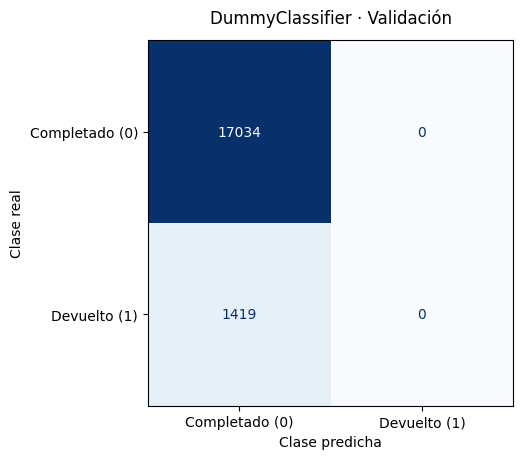


MODELO BASELINE ENTRENADO CORRECTAMENTE


In [17]:
# Crear y entrenar modelo baseline
modelo_base_clf = DummyClassifier(strategy="most_frequent")

modelo_base_clf.fit(X_clf_train_prep, y_clf_train)

# Realizar predicciones
pred_train = modelo_base_clf.predict(X_clf_train_prep)
pred_val = modelo_base_clf.predict(X_clf_val_prep)

proba_train = modelo_base_clf.predict_proba(X_clf_train_prep)[:, 1]

proba_val = modelo_base_clf.predict_proba(X_clf_val_prep)[:, 1]

# Función de evaluación
def evaluar_clasificacion(y_real, y_pred, y_proba):
    return {
        "Accuracy": accuracy_score(y_real, y_pred),
        "Precision": precision_score(
            y_real, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_real, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_real, y_pred, zero_division=0
        ),
        "AUC-ROC": roc_auc_score(y_real, y_proba)
    }

# Tabla de resultados
resultados_clf = pd.DataFrame({
    "Entrenamiento": evaluar_clasificacion(
        y_clf_train, pred_train, proba_train),
    "Validación": evaluar_clasificacion(
        y_clf_val, pred_val, proba_val)}).T

print("RESULTADOS DEL BASELINE - CLASIFICACIÓN")
display(resultados_clf.round(4))

# 5. Matriz de confusión en validación
print("\nMATRIZ DE CONFUSIÓN - VALIDACIÓN")

matriz = confusion_matrix(y_clf_val, pred_val, labels=[0, 1])

graficar_matriz_confusion(matriz, "DummyClassifier · Validación")

print("\nMODELO BASELINE ENTRENADO CORRECTAMENTE")


## 10. Regresión logística exploratoria con balanceo

Se prueba `LogisticRegression(class_weight="balanced")` para dar mayor peso a las devoluciones. **Este es un experimento diagnóstico, no el modelo aceptado finalmente**, porque todavía incluye los puntos de fidelización y se comprobará si producen fuga de información.

RESULTADOS - REGRESIÓN LOGÍSTICA


,Accuracy,Precision,Recall,F1-Score,AUC-ROC
Entrenamiento,0.979,0.784,1.000,0.879,0.993
Validación,0.979,0.782,1.000,0.878,0.993



MATRIZ DE CONFUSIÓN - VALIDACIÓN


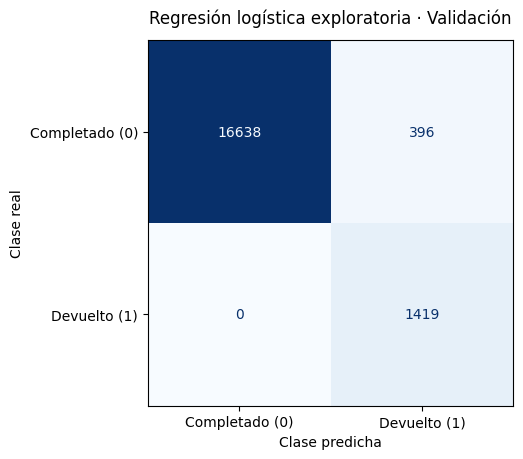


REPORTE DE CLASIFICACIÓN
              precision    recall  f1-score   support

  Completado       1.00      0.98      0.99     17034
    Devuelto       0.78      1.00      0.88      1419

    accuracy                           0.98     18453
   macro avg       0.89      0.99      0.93     18453
weighted avg       0.98      0.98      0.98     18453



In [18]:
# Crear el modelo
modelo_logistico = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)

# Entrenar con datos de entrenamiento
modelo_logistico.fit(X_clf_train_prep, y_clf_train)

# Predicciones
pred_log_train = modelo_logistico.predict(X_clf_train_prep)
pred_log_val = modelo_logistico.predict(X_clf_val_prep)

# Probabilidades
proba_log_train = modelo_logistico.predict_proba( X_clf_train_prep)[:, 1]

proba_log_val = modelo_logistico.predict_proba( X_clf_val_prep)[:, 1]

# Evaluación
resultados_log = pd.DataFrame({
    "Entrenamiento": evaluar_clasificacion(
        y_clf_train, pred_log_train, proba_log_train
    ),
    "Validación": evaluar_clasificacion(
        y_clf_val, pred_log_val, proba_log_val
    )
}).T

print("RESULTADOS - REGRESIÓN LOGÍSTICA")
display(resultados_log.round(4))

# 6. Matriz de confusión
print("\nMATRIZ DE CONFUSIÓN - VALIDACIÓN")

matriz_log = confusion_matrix(y_clf_val, pred_log_val, labels=[0, 1])

graficar_matriz_confusion(matriz_log, "Regresión logística exploratoria · Validación")

# Reporte de clasificación
print("\nREPORTE DE CLASIFICACIÓN")
print(classification_report(
    y_clf_val,
    pred_log_val,
    target_names=["Completado", "Devuelto"],
    zero_division=0
))


### 10.1 Comparación exploratoria y coeficientes

Se comparan las métricas frente al `DummyClassifier` y se examinan los coeficientes de mayor magnitud.

In [19]:
# Comparar métricas de validación
comparacion_modelos = pd.DataFrame({
    "DummyClassifier": resultados_clf.loc["Validación"],
    "Regresión Logística": resultados_log.loc["Validación"]}).T

print("COMPARACIÓN EXPLORATORIA (MODELO CON VARIABLE SOSPECHOSA)")
display(comparacion_modelos.round(4))

# Obtener nombres de las variables transformadas
nombres_variables = (
    pipeline_clf
    .named_steps["preprocesamiento"]
    .get_feature_names_out())

# Obtener coeficientes de la regresión logística
coeficientes = pd.DataFrame({
    "Variable": nombres_variables,
    "Coeficiente": modelo_logistico.coef_[0]
})

# Ordenar por magnitud del coeficiente
coeficientes["Importancia_abs"] = (coeficientes["Coeficiente"].abs())

coeficientes = coeficientes.sort_values( "Importancia_abs", ascending=False)

print("\n10 VARIABLES CON MAYORES COEFICIENTES")
display(coeficientes.head(10))

# 5. Verificar los errores del modelo
print("\nERRORES EN VALIDACIÓN")
print("Falsos positivos:", matriz_log[0, 1])
print("Falsos negativos:", matriz_log[1, 0])


COMPARACIÓN EXPLORATORIA (MODELO CON VARIABLE SOSPECHOSA)


,Accuracy,Precision,Recall,F1-Score,AUC-ROC
DummyClassifier,0.923,0.000,0.000,0.000,0.500
Regresión Logística,0.979,0.782,1.000,0.878,0.993



10 VARIABLES CON MAYORES COEFICIENTES


,Variable,Coeficiente,Importancia_abs
4,numericas__loyalty_points_log,-14.894,14.894
34,categoricas__shipping_method_Economy,-2.961,2.961
18,categoricas__sales_channel_Social Media,-2.928,2.928
15,categoricas__customer_segment_VIP,-2.888,2.888
13,categoricas__customer_segment_Consumer,-2.867,2.867
14,categoricas__customer_segment_Premium,-2.866,2.866
17,categoricas__sales_channel_Mobile App,-2.849,2.849
19,categoricas__sales_channel_Website,-2.820,2.820
37,categoricas__shipping_method_Standard,-2.818,2.818
36,categoricas__shipping_method_Same Day,-2.796,2.796



ERRORES EN VALIDACIÓN
Falsos positivos: 396
Falsos negativos: 0


La logística exploratoria alcanza un **AUC-ROC de 0,993** en validación. `loyalty_points_log` tiene el coeficiente de mayor magnitud dentro de ese modelo. Para interpretar el resultado, se revisa en entrenamiento cómo se distribuyen los puntos según el estado del pedido y si ese patrón podría reflejar información posterior a la compra.

In [20]:
pedidos_train = df_clasificacion.loc[X_clf_train.index]

tabla_puntos_entrenamiento = (
    pedidos_train.groupby("order_status")["loyalty_points_redeemed"]
    .agg(
        pedidos="size",
        mínimo="min",
        mediana="median",
        máximo="max",
        porcentaje_con_cero=lambda puntos: 100 * puntos.eq(0).mean(),
    )
)
display(tabla_puntos_entrenamiento.round(2))

auc_puntos = roc_auc_score(y_clf_train, -pedidos_train["loyalty_points_log"])
print(f"AUC-ROC usando solo los puntos en entrenamiento = {auc_puntos:.4f}")

,pedidos,mínimo,mediana,máximo,porcentaje_con_cero
order_status,,,,,
Completed,79491,0,37.000,1063,2.280
Returned,6623,0,0.000,0,100.000


AUC-ROC usando solo los puntos en entrenamiento = 0.9886


## 11. Corrección de posible fuga de información

En entrenamiento, el **100 % de los pedidos `Returned`** registra cero puntos canjeados, mientras que la mayoría de los `Completed` registra valores positivos. Esto sugiere que el campo puede reflejar el estado final del pedido. Como su disponibilidad al momento de la compra sigue sin verificarse, se excluyen los puntos originales y su transformación de los predictores de regresión y de la clasificación corregida.

La logística corregida usa `class_weight="balanced"` para dar más peso a la clase minoritaria durante el entrenamiento. Así se puede evaluar cuántas devoluciones detecta y cuántas falsas alertas genera con los predictores seleccionados.

RESULTADOS - MODELO SIN VARIABLE SOSPECHOSA


,Accuracy,Precision,Recall,F1-Score,AUC-ROC
Entrenamiento,0.501,0.089,0.593,0.154,0.562
Validación,0.502,0.086,0.573,0.150,0.556



MATRIZ DE CONFUSIÓN - VALIDACIÓN


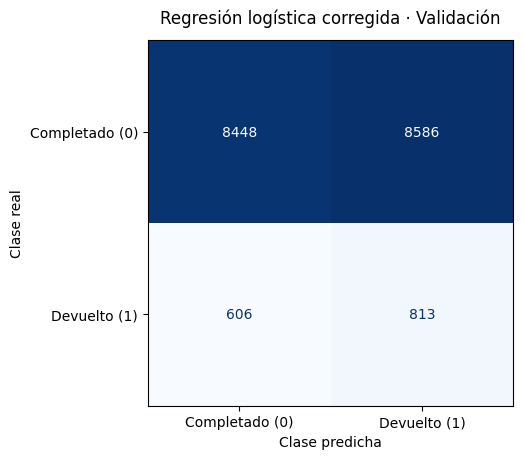


COMPARACIÓN EN VALIDACIÓN


,Accuracy,Precision,Recall,F1-Score,AUC-ROC
Modelo anterior,0.979,0.782,1.000,0.878,0.993
Modelo corregido,0.502,0.086,0.573,0.150,0.556



Variables utilizadas: 11


In [21]:
# Corrección de posible Data Leakage

# Excluir variables sospechosas
columnas_excluir = ["loyalty_points_log",  "loyalty_points_redeemed"]

X_clf_train_clean = X_clf_train.drop( columns=columnas_excluir, errors="ignore")

X_clf_val_clean = X_clf_val.drop( columns=columnas_excluir, errors="ignore")

# Definir variables numéricas y categóricas
numericas_clean = ["customer_age", "quantity", "order_month", "is_weekend"]

categoricas_clean = [
    col for col in X_clf_train_clean.columns
    if col not in numericas_clean]

# Crear nuevo preprocesador
preprocesador_clean = ColumnTransformer([
    ("numericas", StandardScaler(), numericas_clean),
    ("categoricas",
     OneHotEncoder(handle_unknown="ignore"),
     categoricas_clean)
])

# Crear pipeline completo
modelo_logistico_clean = Pipeline([
    ("preprocesador", preprocesador_clean),
    ("modelo", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

# Entrenar únicamente con entrenamiento
modelo_logistico_clean.fit(X_clf_train_clean, y_clf_train)

# Realizar predicciones
pred_clean_train = modelo_logistico_clean.predict(X_clf_train_clean)

pred_clean_val = modelo_logistico_clean.predict(X_clf_val_clean)

proba_clean_train = modelo_logistico_clean.predict_proba(X_clf_train_clean)[:, 1]

proba_clean_val = modelo_logistico_clean.predict_proba(X_clf_val_clean)[:, 1]

# Evaluar el modelo corregido
resultados_clean = pd.DataFrame({
    "Entrenamiento": evaluar_clasificacion(
        y_clf_train, pred_clean_train, proba_clean_train
    ),
    "Validación": evaluar_clasificacion(
        y_clf_val, pred_clean_val, proba_clean_val
    )
}).T

print("RESULTADOS - MODELO SIN VARIABLE SOSPECHOSA")
display(resultados_clean.round(4))

# Matriz de confusión
print("\nMATRIZ DE CONFUSIÓN - VALIDACIÓN")

matriz_clean = confusion_matrix(y_clf_val, pred_clean_val, labels=[0, 1])

graficar_matriz_confusion(matriz_clean, "Regresión logística corregida · Validación")

# Comparación con el modelo anterior
print("\nCOMPARACIÓN EN VALIDACIÓN")

comparacion = pd.DataFrame({
    "Modelo anterior": resultados_log.loc["Validación"],
    "Modelo corregido": resultados_clean.loc["Validación"]
}).T

display(comparacion.round(4))

print("\nVariables utilizadas:",
      X_clf_train_clean.shape[1])


La versión corregida integra codificación, escalamiento y regresión logística en un solo `Pipeline`, ajustado únicamente con entrenamiento. Al excluir los puntos de fidelización, se evita depender de esa señal sospechosa; el menor rendimiento resultante es más creíble para una predicción al momento de la compra.

## 12. Evaluación comparativa válida en validación

La comparación final considera el `DummyClassifier` y la **regresión logística corregida**, con las métricas Accuracy, Precision, Recall, F1, AUC-ROC y Average Precision. Con clases desbalanceadas, la precisión de la clase devuelta y la sensibilidad son más informativas que Accuracy por sí sola.

In [22]:
# Predicciones del modelo Dummy
pred_dummy = modelo_base_clf.predict(X_clf_val_prep)
proba_dummy = modelo_base_clf.predict_proba(
    X_clf_val_prep
)[:, 1]

# Función para comparar modelos
def resumen_modelo(y_real, pred, proba):
    return {
        "Accuracy": accuracy_score(y_real, pred),
        "Precision": precision_score(
            y_real, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_real, pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_real, pred, zero_division=0
        ),
        "AUC-ROC": roc_auc_score(y_real, proba),
        "Average Precision": average_precision_score(
            y_real, proba
        )
    }

# Comparación final
comparacion_final = pd.DataFrame({
    "DummyClassifier": resumen_modelo(
        y_clf_val, pred_dummy, proba_dummy
    ),
    "Regresión logística corregida": resumen_modelo(
        y_clf_val, pred_clean_val, proba_clean_val
    )
}).T

print("COMPARACIÓN FINAL - CLASIFICACIÓN")
display(comparacion_final.round(4))

# Diagnóstico de alertas
print("\nANÁLISIS DE PREDICCIONES")

print("Devoluciones reales:", y_clf_val.sum())
print("Devoluciones predichas:", pred_clean_val.sum())

print("Porcentaje de pedidos marcados como devolución:",
      round(pred_clean_val.mean() * 100, 2), "%")

print("Tasa real de devoluciones:",
      round(y_clf_val.mean() * 100, 2), "%")

print("\nEVALUACIÓN COMPLETADA")


COMPARACIÓN FINAL - CLASIFICACIÓN


,Accuracy,Precision,Recall,F1-Score,AUC-ROC,Average Precision
DummyClassifier,0.923,0.000,0.000,0.000,0.500,0.077
Regresión logística corregida,0.502,0.086,0.573,0.150,0.556,0.088



ANÁLISIS DE PREDICCIONES
Devoluciones reales: 1419
Devoluciones predichas: 9399
Porcentaje de pedidos marcados como devolución: 50.93 %
Tasa real de devoluciones: 7.69 %

EVALUACIÓN COMPLETADA


**Regresión.** En validación, la regresión lineal con `quantity` obtuvo un **MAE de 619,84 USD**, un **RMSE de 894,06 USD** y un **R² de 0,352**. El modelo explica aproximadamente el 35,2 % de la variación de la venta neta en esta partición. La diferencia entre MAE y RMSE muestra el peso de los errores más grandes. Estos valores sirven como referencia para comparar los modelos de la Fase 3.

**Clasificación.** El `DummyClassifier` logra **92,3 % de exactitud** al etiquetar todos los pedidos como `Completed`, con **0 % de sensibilidad** para devoluciones. La logística corregida identifica el **57,3 %** de las devoluciones con una **precisión del 8,6 %**. Marcó el **50,93 %** de los pedidos como posibles devoluciones frente a una tasa real del **7,69 %**, lo que explica el volumen de falsas alarmas. El **AUC-ROC de 0,556** y la **Average Precision de 0,088** muestran que su capacidad para distinguir las clases sigue siendo limitada.

## 13. Resumen del preprocesamiento y los modelos base

Se consolidan las métricas de validación, el número de registros y las variables disponibles para continuar el proyecto en la siguiente fase.

In [23]:
# Resumen de regresión
resumen_regresion = resultados_reg.loc[["Entrenamiento", "Validación"]].copy()

print("BASELINE DE REGRESIÓN LINEAL")
print("Variable objetivo: net_sales (USD)")
print("Predictor: quantity")
display(resumen_regresion.round(4))

# Resumen de clasificación
print("\nBASELINE DE CLASIFICACIÓN")
print("Variable objetivo: target_returned")

display(comparacion_final.round(4))

# Resumen de preparación de datos
resumen_fase2 = pd.DataFrame({
    "Indicador": [
        "Registros originales",
        "Variables después de ingeniería",
        "Registros para regresión",
        "Registros para clasificación",
        "Variables predictoras de regresión",
        "Variables predictoras de clasificación corregida",
        "Proporción de devoluciones (%)"
    ],
    "Resultado": [
        len(df_master),
        df_master.shape[1],
        len(df_regresion),
        len(df_clasificacion),
        X_reg.shape[1],
        X_clf_train_clean.shape[1],
        round(y_clf.mean() * 100, 2)
    ]
})

print("\nRESUMEN GENERAL DE LA FASE 2")
display(resumen_fase2)


BASELINE DE REGRESIÓN LINEAL
Variable objetivo: net_sales (USD)
Predictor: quantity


,MAE,RMSE,R2
Entrenamiento,625.480,907.744,0.358
Validación,619.839,894.064,0.352



BASELINE DE CLASIFICACIÓN
Variable objetivo: target_returned


,Accuracy,Precision,Recall,F1-Score,AUC-ROC,Average Precision
DummyClassifier,0.923,0.000,0.000,0.000,0.500,0.077
Regresión logística corregida,0.502,0.086,0.573,0.150,0.556,0.088



RESUMEN GENERAL DE LA FASE 2


,Indicador,Resultado
0,Registros originales,"138,116.000"
1,Variables después de ingeniería,22.000
2,Registros para regresión,"82,600.000"
3,Registros para clasificación,"123,021.000"
4,Variables predictoras de regresión,10.000
5,Variables predictoras de clasificación corregida,11.000
6,Proporción de devoluciones (%),7.690


## 14. Exportación de datos para la Fase 3

Se guardan las tres particiones de cada tarea supervisada, las métricas de referencia y la tabla de pedidos en USD que se usará para la segmentación. La Fase 3 recupera estos elementos desde `fase2_para_fase3.joblib`.

In [24]:
import joblib

# Conjunto de prueba sin variables sospechosas de fuga
X_clf_test_clean = X_clf_test.drop(
    columns=["loyalty_points_log", "loyalty_points_redeemed"],
    errors="ignore"
)

# Datos para clustering: ventas expresadas en USD
df_clustering = df_regresion[
    ["customer_age", "quantity", "net_sales",
     "order_month", "is_weekend"]
].copy()

# Consolidar los datos necesarios para la Fase 3
datos_fase3 = {
    "regresion": {
        "X_train": X_reg_train,
        "X_val": X_reg_val,
        "X_test": X_reg_test,
        "y_train": y_reg_train,
        "y_val": y_reg_val,
        "y_test": y_reg_test
    },
    "clasificacion": {
        "X_train": X_clf_train_clean,
        "X_val": X_clf_val_clean,
        "X_test": X_clf_test_clean,
        "y_train": y_clf_train,
        "y_val": y_clf_val,
        "y_test": y_clf_test
    },
    "clustering": df_clustering,
    "baseline_regresion": resultados_reg,
    "baseline_clasificacion": comparacion_final
}
# Conservar el DataFrame procesado
datos_fase3["df_master"] = df_master.copy()

# Guardar archivo
joblib.dump(
    datos_fase3,
    "fase2_para_fase3.joblib",
    compress=3
)

print("Datos exportados correctamente para la Fase 3")


Datos exportados correctamente para la Fase 3
